In [5]:
from pathlib import Path
import pandas as pd
import torch
from torch_geometric.data import Data

ROOT = Path.cwd() if (Path.cwd() / "notebooks").is_dir() else Path.cwd().parent

features_path = ROOT / "data/processed/protein_sequence_features_aac.parquet"
edges_path = ROOT / "data/processed/ppi_edges_score_700.parquet"
labels_path = ROOT / "data/processed/go_mf_labels_min_support_100.parquet"
terms_path = ROOT / "data/processed/go_mf_target_terms_min_support_100.csv"

feature_df = pd.read_parquet(features_path)
ppi_edges = pd.read_parquet(edges_path)
labels_df = pd.read_parquet(labels_path)
target_terms = pd.read_csv(terms_path)

print("Protein nodes:", len(feature_df))
print("Undirected PPI edges:", len(ppi_edges))
print("GO label pairs:", len(labels_df))
print("Target GO labels:", len(target_terms))

c:\Users\rajdeep\Desktop\Capstone Project_GNN\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\rajdeep\Desktop\Capstone Project_GNN\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Protein nodes: 18841
Undirected PPI edges: 533818
GO label pairs: 29730
Target GO labels: 96


In [6]:
# STRING ID → permanent node index mapping
string_id_to_node = pd.Series(
    feature_df["node_index"].values,
    index=feature_df["string_id"],
).to_dict()

ppi_edges["source_node"] = ppi_edges["protein1"].map(string_id_to_node)
ppi_edges["target_node"] = ppi_edges["protein2"].map(string_id_to_node)

assert ppi_edges["source_node"].notna().all()
assert ppi_edges["target_node"].notna().all()

source_nodes = torch.tensor(
    ppi_edges["source_node"].to_numpy(),
    dtype=torch.long,
)

target_nodes = torch.tensor(
    ppi_edges["target_node"].to_numpy(),
    dtype=torch.long,
)

# STRING interactions are undirected, so PyG graph mein both directions add karenge.
edge_index = torch.stack(
    [
        torch.cat([source_nodes, target_nodes]),
        torch.cat([target_nodes, source_nodes]),
    ],
    dim=0,
)

forward_weights = torch.tensor(
    ppi_edges["edge_weight"].to_numpy(),
    dtype=torch.float32,
)

edge_weight = torch.cat([forward_weights, forward_weights])

print("Directed edges for PyG:", f"{edge_index.shape[1]:,}")
print("Edge-weight shape:", edge_weight.shape)

Directed edges for PyG: 1,067,636
Edge-weight shape: torch.Size([1067636])


In [7]:
AA_ALPHABET = list("ACDEFGHIKLMNPQRSTVWY")

feature_columns = (
    [f"aa_{aa}" for aa in AA_ALPHABET]
    + ["unknown_residue_fraction", "log_sequence_length"]
)

x = torch.tensor(
    feature_df[feature_columns].to_numpy(dtype="float32"),
    dtype=torch.float32,
)

print("Node-feature matrix shape:", x.shape)
print("Features per protein:", len(feature_columns))

Node-feature matrix shape: torch.Size([18841, 22])
Features per protein: 22


In [8]:
# UniProt ID → node index mapping for GO labels
uniprot_id_to_node = pd.Series(
    feature_df["node_index"].values,
    index=feature_df["uniprot_id"],
).to_dict()

labels_df["node_index"] = labels_df["uniprot_id"].map(uniprot_id_to_node)

assert labels_df["node_index"].notna().all()

num_nodes = len(feature_df)
num_labels = len(target_terms)

# Multi-label target matrix: y[node, label] is 1 when that protein has the GO term.
y = torch.zeros((num_nodes, num_labels), dtype=torch.float32)

label_node_indices = torch.tensor(
    labels_df["node_index"].to_numpy(),
    dtype=torch.long,
)

label_indices = torch.tensor(
    labels_df["label_index"].to_numpy(),
    dtype=torch.long,
)

y[label_node_indices, label_indices] = 1.0

labeled_mask = y.sum(dim=1) > 0

print("Target matrix shape:", y.shape)
print("Proteins with at least one target label:", int(labeled_mask.sum()))
print(
    "Average labels per labelled protein:",
    round(float(y[labeled_mask].sum(dim=1).mean()), 2),
)

Target matrix shape: torch.Size([18841, 96])
Proteins with at least one target label: 12020
Average labels per labelled protein: 2.47


In [9]:
graph = Data(
    x=x,
    edge_index=edge_index,
    edge_weight=edge_weight,
    y=y,
    labeled_mask=labeled_mask,
)

graph.validate(raise_on_error=True)

print(graph)
print("\nNumber of nodes:", graph.num_nodes)
print("Number of directed edges:", graph.num_edges)
print("Number of labels:", graph.y.shape[1])

Data(x=[18841, 22], edge_index=[2, 1067636], y=[18841, 96], edge_weight=[1067636], labeled_mask=[18841])

Number of nodes: 18841
Number of directed edges: 1067636
Number of labels: 96


In [10]:
output_path = ROOT / "data/processed/protein_function_graph_aac_score700.pt"

torch.save(graph, output_path)

print("Saved:", output_path)
print(f"File size: {output_path.stat().st_size / 1024**2:.2f} MB")

Saved: c:\Users\rajdeep\Desktop\Capstone Project_GNN\data\processed\protein_function_graph_aac_score700.pt
File size: 28.87 MB


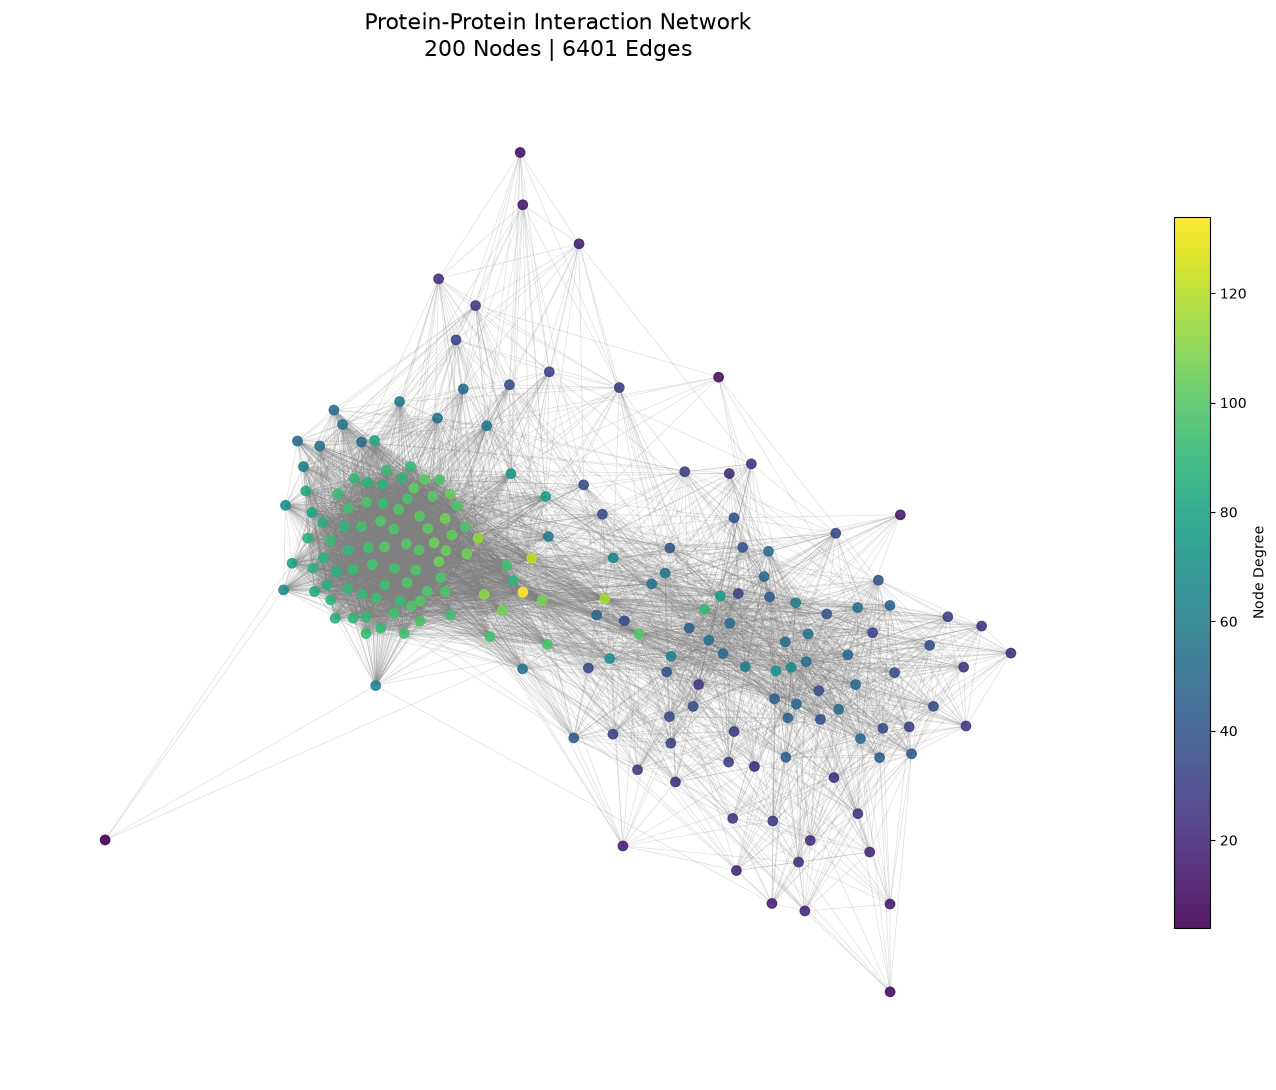

Visualization saved successfully!
Visualized nodes: 200
Visualized edges: 6401
Visualization saved successfully!
Visualized nodes: 200
Visualized edges: 6401


In [12]:

import torch
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

# 1. Get graph edges and weights
edge_index = graph.edge_index.cpu()
edge_weight = graph.edge_weight.cpu()

# 2. Calculate degree of each protein
num_nodes = graph.num_nodes

degree = torch.bincount(
    edge_index[0],
    minlength=num_nodes
)

# 3. Select 200 highly connected protein nodes
num_selected = 200

selected_nodes = torch.topk(
    degree,
    k=num_selected
).indices

selected_set = set(selected_nodes.tolist())

# 4. Select edges connecting these nodes
source = edge_index[0].tolist()
target = edge_index[1].tolist()
weights = edge_weight.tolist()

G = nx.Graph()

for node in selected_nodes.tolist():
    G.add_node(node)

for u, v, w in zip(source, target, weights):
    if u in selected_set and v in selected_set and u != v:
        G.add_edge(u, v, weight=float(w))

# 5. Draw the graph

# 5. Draw the graph

fig, ax = plt.subplots(figsize=(14, 11))

pos = nx.spring_layout(
    G,
    seed=42,
    k=0.25,
    iterations=50
)

node_degrees = dict(G.degree())
node_colors = [node_degrees[n] for n in G.nodes()]

# Draw nodes
nodes = nx.draw_networkx_nodes(
    G,
    pos,
    node_size=45,
    node_color=node_colors,
    cmap=plt.cm.viridis,
    alpha=0.9,
    ax=ax
)

# Draw edges
nx.draw_networkx_edges(
    G,
    pos,
    alpha=0.25,
    width=0.5,
    edge_color="gray",
    ax=ax
)

ax.set_title(
    f"Protein-Protein Interaction Network\n"
    f"{G.number_of_nodes()} Nodes | {G.number_of_edges()} Edges",
    fontsize=16
)

ax.axis("off")

# Correct colorbar configuration
fig.colorbar(
    nodes,
    ax=ax,
    label="Node Degree",
    shrink=0.7
)

plt.tight_layout()

plt.savefig(
    "PPI_Graph_Visualization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Visualization saved successfully!")
print("Visualized nodes:", G.number_of_nodes())
print("Visualized edges:", G.number_of_edges())


print("Visualization saved successfully!")
print("Visualized nodes:", G.number_of_nodes())
print("Visualized edges:", G.number_of_edges())
